# Monotonicity constraints and variable selection in pooled data

A dose–response study pools patients from two sites. Within each site, higher dose
raises the response. The second site treats sicker patients, uses higher doses, and
starts from a lower baseline, so the pooled relation can fall across the gap between the
sites even though both within-site relations rise.

A free smooth can represent that pooled fall without selecting the site indicator. The
analyst instead supplies the mechanistic claim that dose cannot lower the response. A
monotone smooth cannot absorb the between-site drop, so the site term must compete for
it. The study measures how this constraint changes both the dose curve and variable
selection.

This case teaches why pooled monotonicity and within-site monotonicity are different
claims. Simulated sites make it possible to check both the estimated dose curve and the
model's selection of the site term.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether a shape constraint makes the model select the site variable that explains a pooled dose–response curve |
| **Observed response** | a simulated outcome from two sites |
| **Estimand** | which variables the path selects, and the within-site dose–response shape |
| **Units** | simulated, arbitrary scale |
| **Sampling unit** | one simulated patient, nested in one of two sites |
| **Dependence** | patients are clustered by site, and the sites differ in both dose assignment and baseline — the structure the study is about |
| **Split / resampling unit** | the patient; a site-level split is not used because there are only two sites |
| **Tuning** | fixed `mstop` so the constraint is the only difference |
| **Uncertainty** | repeated simulation |
| **Claim type** | causal within the simulation |
:::


## The data

Patients come from two sites. Site 1 treats sicker patients: it administers higher doses, and its patients enter the study with a lower baseline response. A patient's dose falls into one of two clusters — around 2 for site 0, around 6 for site 1 — and the site is which cluster the dose falls in,

$$
\text{dose} \sim 0.5\,N(2,\ 0.7) + 0.5\,N(6,\ 0.7), \qquad \text{site} = \mathbb{1}\{\text{dose} > 4\}.
$$

Within each site the response rises by 1.0 per unit dose, and site 1's baseline is 3.5 lower,

$$
y = W + 4 - 3.5\,\text{site} + 1.0\,\text{dose} + \varepsilon_y, \qquad
W \sim N(0,\ 1.5), \quad \varepsilon_y \sim N(0,\ 0.6).
$$

The term $W$ is an unmeasured patient component — severity, genetics, history — drawn independently of dose and site. It is not a candidate variable; to the model it is residual noise, but it is large enough that the raw response cloud hides the two populations. The candidate set also includes a noise variable $S$ drawn independently of everything else; it carries no signal and should not be selected.

In [1]:
import warnings
# Fix the random draw so the resampling result is reproducible.
import numpy as np
import polars as pl

import mboostrs as mb

n_obs = 300


def generate(rng, rows=n_obs, separated=True):
    if separated:
        dose = np.where(rng.random(rows) < 0.5,
                        rng.normal(2.0, 0.7, rows),
                        rng.normal(6.0, 0.7, rows))
        site = (dose > 4.0).astype(float)
    else:
        dose = rng.normal(4.0, 1.6, rows)
        site = (rng.random(rows) < 0.5).astype(float)
    W = rng.normal(0.0, 1.5, rows)
    y = W + 4.0 - 3.5 * site + 1.0 * dose + rng.normal(0, 0.6, rows)
    S = rng.normal(0, 1, rows)
    return {"dose": dose, "site": site, "y": y, "S": S}


rng = np.random.default_rng(0)
data = generate(rng)

print(f"n = {n_obs}")
print(f"corr(dose, y) pooled          {np.corrcoef(data['dose'], data['y'])[0, 1]:.3f}")
for s in (0, 1):
    mask = data["site"] == s
    print(f"corr(dose, y) within site {s}   "
          f"{np.corrcoef(data['dose'][mask], data['y'][mask])[0, 1]:.3f}")


n = 300
corr(dose, y) pooled          0.212
corr(dose, y) within site 0   0.355
corr(dose, y) within site 1   0.370


The pooled correlation is 0.21, positive but weak. Inside each site it is 0.36 and 0.37. The offset between the sites is part of the reason the pooled relation is weaker than the within-site ones: patients at the high end of the dose scale are the sicker site, and they start from a baseline 3.5 lower, so a high dose does not buy the response it buys within either site. The unmeasured component $W$ dilutes every correlation further, and it is why the response values in the scatter below form one wide noisy band: the within-site rise and the 3.5-point step are not visible in the raw data.

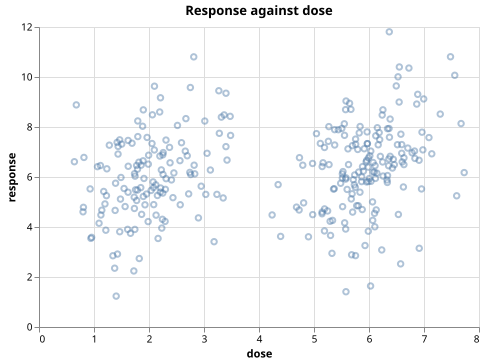

In [2]:
import altair as alt

scatter = alt.Chart(pl.DataFrame(data)).mark_point(
    size=30, opacity=0.45, color="#4e79a7"
).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("y:Q", title="response"),
)
scatter.properties(width=440, height=300).properties(title="Response against dose")

The two dose regions correspond to the two simulated sites. A free dose spline can fit the 3.5-point between-site offset by falling across the gap, reducing the residual improvement available to the site indicator. An increasing constraint forbids that fall. The comparison below measures whether this causes the site term to enter the boosting path.

## Dose-response within each site

The causal effect is known because the data are simulated: holding the site fixed, each unit of dose raises the response by 1.0, at every dose. The marginal relation is the same step that generated the data — rising with slope 1 inside each site, dropping 3.5 where the dose crosses the site boundary.

The comparison below is between the fitted partial effect of dose — the model's prediction with the site held at its mean, centred to average zero — and the truth line $\text{dose} - 4$, the within-site causal effect. A fit that recovers the causal effect produces a curve close to that line; a fit that folds the between-site offset into the dose curve bends away from it.

## Free and monotone fits

Both fits take the candidates dose, site, and S. The dose term is a P-spline with four degrees of freedom, free (`bbs`) or constrained to be increasing (`bmono`, using the exact quadratic-programming solver so the constraint holds at every iteration). Both run the same budget of 300 boosting steps at learning rate 0.1. The only difference is the constraint: the monotone fit is told, from mechanism rather than from the data, that a higher dose cannot lower the response. The table records how each fit spent its steps and how far its fitted dose curve sits from the truth.

In [3]:
import collections

grid_dose = np.linspace(1, 7, 61)

truth_curve = grid_dose - grid_dose.mean()

i5 = int(np.abs(grid_dose - 5.0).argmin())

candidates = " + bols(site) + bols(S)"

dose_terms = {
    "free": "bbs(dose, df=4)",
    "monotone": "bmono(dose, df=4, constraint='increasing', type='quad.prog')",
}

def partial_effect(model, source=data, grid=grid_dose):
    newdata = {
        "dose": grid,
        "site": np.full(len(grid), float(source["site"].mean())),
        "S": np.full(len(grid), float(source["S"].mean())),
    }
    fitted = np.asarray(model.predict(newdata=newdata)).ravel()
    return fitted - fitted.mean()

rows = []


In [4]:
for shape, dose_term in dose_terms.items():
    model = mb.gamboost(f"y ~ {dose_term}{candidates}", data=data,
                        family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
    steps = collections.Counter(list(model.selected))
    curve = partial_effect(model)
    rows.append({
        "dose learner": shape,
        "steps on dose": steps.get("dose", 0),
        "steps on site": steps.get("site", 0),
        "steps on S": steps.get("S", 0),
        "distance from the truth": round(float(np.abs(curve - truth_curve).mean()), 3),
        "falling intervals": int((np.diff(curve) < -1e-6).sum()),
        "dose effect at 5.0": round(float(curve[i5]), 3),
    })

display(pl.DataFrame(rows))


dose learner,steps on dose,steps on site,steps on S,distance from the truth,falling intervals,dose effect at 5.0
str,i64,i64,i64,f64,i64,f64
"""free""",288,0,12,1.517,18,-0.614
"""monotone""",179,106,15,1.02,0,0.041


The free fit spends nearly all 300 steps on the dose spline — 288 of them — and does not select site; the constrained fit splits its steps, 179 on dose and 106 on site. The noise variable $S$ receives 12 steps in the free fit and 15 in the constrained fit. Both paths therefore select some noise; the difference of interest is that the constrained fit also selects site.

It also moves the estimate toward the truth: the distance from the fitted dose curve to the causal effect falls from 1.52 to 1.02, and the fitted curve stops falling anywhere on the grid — 18 falling intervals become none. The direction is the sharpest difference. At a dose of 5, where the truth is +1.0, the free fit estimates −0.61 and the constrained fit +0.04.

## Fitted dose-response curves

The chart overlays the two fitted partial effects on the truth. The free curve follows the pooled relation: it rises through the low-dose site, then bends down across the dose gap between the sites, and the fitted drug effect turns negative in the middle of the dose range — exactly where the truth is at its most positive. The constrained curve can bend but cannot decrease, so it preserves the supplied direction across the whole range. It still smooths the step, rising more slowly across the gap, but it never contradicts the causal direction.

In [5]:
frames = []
# Plot the quantities interpreted in the following paragraph.
for shape in dose_terms:
    model = mb.gamboost(f"y ~ {dose_terms[shape]}{candidates}", data=data,
                        family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
    curve = partial_effect(model)
    frames.append(pl.DataFrame({
        "dose": grid_dose, "response": curve,
        "curve": ["free fit" if shape == "free" else "monotone fit"] * len(grid_dose),
    }))

frames.append(pl.DataFrame({
    "dose": grid_dose, "response": truth_curve,
    "curve": ["true causal effect"] * len(grid_dose),
}))

curves = pl.concat(frames)

colour = alt.Color(
    "curve:N", title=None,
    scale=alt.Scale(domain=["true causal effect", "free fit", "monotone fit"],
                    range=["#bbbbbb", "#e15759", "#4e79a7"]),
)

truth = alt.Chart(curves).transform_filter(
    alt.datum.curve == "true causal effect"
).mark_line(strokeWidth=7, opacity=0.9).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("response:Q", title="partial effect of dose, centred to average zero"),
    color=colour,
)


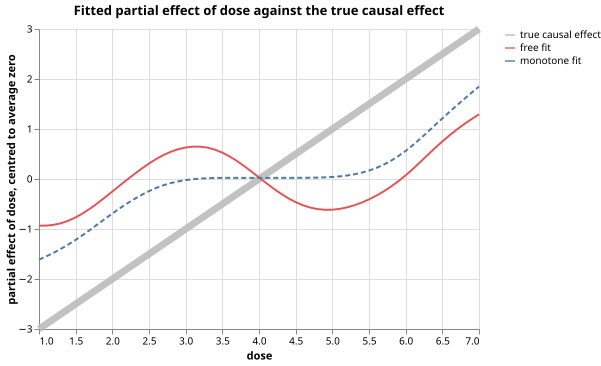

In [6]:
fitted = alt.Chart(curves).transform_filter(
    alt.datum.curve != "true causal effect"
).mark_line(strokeWidth=2).encode(
    x=alt.X("dose:Q"), y=alt.Y("response:Q"), color=colour,
    strokeDash=alt.condition(alt.datum.curve == "monotone fit",
                             alt.value([5, 3]), alt.value([1, 0])),
)

alt.layer(truth, fitted).properties(width=440, height=300).properties(
    title="Fitted partial effect of dose against the true causal effect"
)


## Site offset and the dose curve

The mechanism is direct. The free spline is flexible enough to absorb the 3.5-unit offset between the sites into a downward bend of the dose curve, and it does. Once the bend carries the offset, the model has no use for the site variable, so site is never selected. The monotone spline cannot bend, so the offset has to be carried by a variable that separates the sites — and only site does. The constrained fit selects it.

This is the same mechanism the earlier study in this book identified for a single population: a shape constraint changes the fitted coefficient of its own learner, and it changes the selection of the other learners only when those learners were compensating for the part of the fit the constraint now forbids. Here the free fit does want the forbidden bend — it needs it to absorb the between-site difference — so removing the bend sends that difference to the site variable.

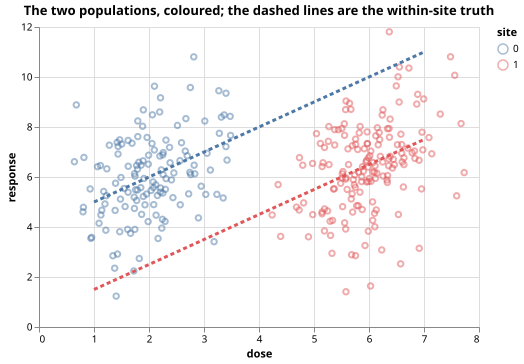

In [7]:
plot_data = pl.DataFrame(data).with_columns(pl.col("site").cast(pl.Int64).cast(pl.Utf8))
scatter = alt.Chart(plot_data).mark_point(size=30, opacity=0.5).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("y:Q", title="response"),
    color=alt.Color("site:N", title="site",
                    scale=alt.Scale(domain=["0", "1"], range=["#4e79a7", "#e15759"])),
)
truth_lines = pl.DataFrame({
    "dose": np.concatenate([grid_dose, grid_dose]),
    "y": np.concatenate([4.0 + grid_dose, 0.5 + grid_dose]),
    "site": ["0"] * 61 + ["1"] * 61,
})
lines = alt.Chart(truth_lines).mark_line(strokeWidth=3, strokeDash=[4, 3]).encode(
    x=alt.X("dose:Q"), y=alt.Y("y:Q"),
    color=alt.Color("site:N", scale=alt.Scale(domain=["0", "1"], range=["#4e79a7", "#e15759"])),
)
(scatter + lines).properties(width=440, height=300).properties(
    title="The two populations, coloured; the dashed lines are the within-site truth"
)

## Results over twenty data sets

The single sample is one draw. Averaged over twenty fresh data sets, the pattern is the same.

In [8]:
def one_run(seed):
    d = generate(np.random.default_rng(seed))
    out = {}
    for shape, dose_term in dose_terms.items():
        model = mb.gamboost(f"y ~ {dose_term}{candidates}", data=d,
                            family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
        steps = collections.Counter(list(model.selected))
        curve = partial_effect(model, source=d)
        out[shape] = {
            "steps on site": steps.get("site", 0),
            "distance": float(np.abs(curve - truth_curve).mean()),
            "falling": int((np.diff(curve) < -1e-6).sum()),
        }
    return out
# Fix the random draw so the resampling result is reproducible.

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    acc = {}
    for seed in range(1, 21):
        for k, v in one_run(seed).items():
            acc.setdefault(k, []).append(v)

summary = []
for shape in dose_terms:
    vs = acc[shape]
    summary.append({
        "dose learner": shape,
        "samples selecting site (of 20)": sum(v["steps on site"] > 0 for v in vs),
        "mean steps on site": round(float(np.mean([v["steps on site"] for v in vs])), 1),
        "mean distance from the truth": round(float(np.mean([v["distance"] for v in vs])), 3),
        "mean falling intervals": round(float(np.mean([v["falling"] for v in vs])), 1),
    })
display(pl.DataFrame(summary))


dose learner,samples selecting site (of 20),mean steps on site,mean distance from the truth,mean falling intervals
str,i64,f64,f64,f64
"""free""",3,3.7,1.493,18.3
"""monotone""",20,101.5,0.949,0.0


Site enters 3 of 20 free fits and 20 of 20 constrained fits. The mean distance to the truth is 1.49 free against 0.95 constrained, and the free fit falls on about 18 of the 60 dose-grid intervals on average while the constrained fit falls on none.

## Overlapping dose ranges

The bend only exists if the dose curve is able to carry the offset, and that requires the two sites to occupy separate parts of the dose range. If both sites drew their doses from the same range, a dose spline — free or constrained — cannot separate them, and the offset falls on the site variable regardless of the constraint. The table counts, over twenty fresh data sets, how often each fit selects site under the two dose designs.

In [9]:
overlap_rows = []
for separated, label in [(True, "sites separated in dose"),
                         (False, "sites share the same dose range")]:
    for shape, dose_term in dose_terms.items():
        selected = 0
        for seed in range(1, 21):
            d = generate(np.random.default_rng(seed), separated=separated)
            model = mb.gamboost(f"y ~ {dose_term}{candidates}", data=d,
                                family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
            if collections.Counter(list(model.selected)).get("site", 0) > 0:
                selected += 1
        overlap_rows.append({
            "dose design": label,
            "dose learner": shape,
            "samples selecting site (of 20)": selected,
        })
display(pl.DataFrame(overlap_rows))

dose design,dose learner,samples selecting site (of 20)
str,str,i64
"""sites separated in dose""","""free""",3
"""sites separated in dose""","""monotone""",20
"""sites share the same dose rang…","""free""",20
"""sites share the same dose rang…","""monotone""",20


With the sites separated in dose, the free fit selects site in 3 of 20 samples and the constrained fit in all 20. With both sites drawing their doses from the same range, both fits select site in all 20. In the overlapping design there is no forbidden bend for the constraint to divert, and the constraint changes nothing about selection. The constraint acts on selection exactly where the free fit was using the forbidden bend.

## Conclusions

With the sites separated in dose, the monotonicity constraint increases selection of site from 3 of 20 free fits to 20 of 20 constrained fits. The constraint acts on selection exactly where the free fit was using the forbidden bend — with overlapping doses it changes nothing. And where it acts, the constrained estimate is closer to the truth.

Two limits. The group variable has to be measured and in the candidate set: the constraint diverts the offset to a variable that exists, it does not create one. And the constraint knowledge must be right inside every population: the design assumed that more of the drug raises the response in both sites, and a constraint imposed from mechanism can conceal a subpopulation in which the effect runs the other way by folding it into a compromise shape instead of displaying it.

In [10]:
model = mb.gamboost(
    "y ~ bmono(dose, df=4, constraint='increasing', type='quad.prog') + bols(S)",
    data=data, family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
newdata = {"dose": grid_dose, "S": np.full(len(grid_dose), float(data["S"].mean()))}
curve = np.asarray(model.predict(newdata=newdata)).ravel()
curve = curve - curve.mean()
print(f"distance from the truth              {np.abs(curve - truth_curve).mean():.3f}")
print(f"fitted range of the dose effect      {curve[-1] - curve[0]:.3f}   (truth {truth_curve[-1] - truth_curve[0]:.3f})")

distance from the truth              1.232
fitted range of the dose effect      2.307   (truth 6.000)


With the site variable removed from the candidates, the constrained fit cannot represent the step at all. It flattens the dose–response: the fitted range of the dose effect compresses to about 2.3 against the truth's 6.0, and the distance to the truth (1.23) is worse than the constrained fit that had the site (1.02), though still better than the free fit (1.52).

The constrained fit is also closer to the truth but not exact: it smooths the 3.5-unit step into a ramp across the dose gap, so it still understates the slope in the transition zone. The comparison rests on a simulated truth with a known monotone effect; where the direction itself is in doubt, a monotone fit has two explanations and this study does not separate them.

```{bibliography}
:filter: docname in docnames
```